# Klasifikace satelitních snímků EuroSAT (RGB) — Milestone 1

**Projekt:** Multitřídní klasifikace satelitních snímků zemského pokryvu (Land Use / Land Cover)  
**Architektura:** Vlastní konvoluční neuronová síť (Baseline CNN) v nativním PyTorch  
**Dataset:** EuroSAT RGB (27 000 snímků, 64×64 px, 10 tříd, rozdělení 70 / 20 / 10)  
**Zdroj dat:** [Kaggle — EuroSAT Dataset](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset)

---
# 1. Příprava výpočetního prostředí a načtení dat

In [2]:
# 1.1 Příprava prostředí a stažení datasetu (Google Colab / lokální prostředí)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()

if IN_COLAB:
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            print("Připojuji Google Disk...")
            drive.mount("/content/drive")
        else:
            print("Google Disk je již připojen.")
    except Exception as e:
        print(f"Poznámka k připojení disku: {e}")

    # Kandidátní cesty k EuroSAT.zip na Google Disku
    drive_candidates = [
        Path("/content/drive/MyDrive/Colab Notebooks/ML_project/EuroSAT.zip"),
        Path("/content/drive/MyDrive/Colab Notebooks/EuroSAT.zip"),
        Path("/content/drive/MyDrive/ML_project/EuroSAT.zip"),
        Path("/content/drive/MyDrive/EuroSAT.zip"),
    ]

    zip_file = next((p for p in drive_candidates if p.exists()), None)
    if zip_file is None and Path("/content/drive/MyDrive").exists():
        print("Hledám EuroSAT.zip na Google Disku...")
        found_zips = list(Path("/content/drive/MyDrive").glob("**/EuroSAT.zip"))
        if found_zips:
            zip_file = found_zips[0]

    target_dir = Path("/content/EuroSAT")

    if zip_file is not None:
        print(f"Nalezen archiv: {zip_file}")
        # Rozbalíme pouze pokud na lokálním SSD ještě chybí train.csv
        if not (target_dir / "train.csv").exists():
            print("Rozbaluji EuroSAT.zip na lokální SSD instance (/content/)... Tato operace trvá jen pár sekund.")
            !unzip -q "{zip_file}" -d /content/
            # Pokud byl archiv zabalen bez nadřazené složky EuroSAT, vytvoříme ji
            if not target_dir.exists() and Path("/content/AnnualCrop").exists():
                !mkdir -p /content/EuroSAT
                !mv /content/AnnualCrop /content/Forest /content/HerbaceousVegetation /content/Highway /content/Industrial /content/Pasture /content/PermanentCrop /content/Residential /content/River /content/SeaLake /content/*.csv /content/*.json /content/EuroSAT/ 2>/dev/null || true
            print("Rozbalení dokončeno! Data jsou na rychlém SSD.")
        else:
            print("Dataset je již rozbalen v /content/EuroSAT.")
    else:
        print("VAROVÁNÍ: EuroSAT.zip nebyl nalezen na Google Disku! Zkontrolujte složku na Disku.")
else:
    print("Běžíme lokálně na PC — použije se lokální složka EuroSAT.")


Mounted at /content/drive
Nalezen archiv: /content/drive/MyDrive/Colab Notebooks/ML_project/EuroSAT.zip
Rozbaluji EuroSAT.zip na lokální SSD instance (/content/)... Tato operace trvá jen pár sekund.
Rozbalení dokončeno! Data jsou na rychlém SSD.


In [3]:
# 1.2 Instalace torchinfo (pro vizualizaci architektur neuronových sítí)
try:
    import torchinfo
except ImportError:
    !pip install -q torchinfo
    import torchinfo
print("torchinfo připraveno.")

torchinfo připraveno.


In [4]:
# 1.3 Importy knihoven a Device setup
import os
import numpy as np
import pandas as pd
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torch.nn.functional as F
from torchvision import transforms

from sklearn.metrics import classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Automatická volba zařízení: GPU (CUDA) v Colabu, CPU lokálně
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch verze:", torch.__version__)
print("Aktivní výpočetní zařízení (Device):", device)


PyTorch verze: 2.11.0+cu130
Aktivní výpočetní zařízení (Device): cuda


In [5]:
# 1.4 Automatické vyhledání cesty k datasetu EuroSAT
candidate_paths = [
    Path("EuroSAT"),          # Lokální složka na PC
    Path("/content/EuroSAT"), # Lokální SSD v Colabu
    Path("/content"),         # Pokud je rozbaleno přímo v /content
]

DATA_DIR = None
for p in candidate_paths:
    if (p / "train.csv").exists():
        DATA_DIR = p
        break

# Fallback: rekurzivní vyhledání train.csv
if DATA_DIR is None:
    search_root = Path("/content") if IN_COLAB else Path(".")
    found = list(search_root.glob("**/train.csv"))
    if found:
        DATA_DIR = found[0].parent

assert DATA_DIR is not None, "Složka s datasetem EuroSAT (obsahující train.csv) nebyla nalezena!"

# Kontrola kompatibility cest v CSV s reálnou složkou obrázků
sample_check = pd.read_csv(DATA_DIR / "train.csv", nrows=1)
sample_fname = sample_check["Filename"].iloc[0]
if not (DATA_DIR / sample_fname).exists():
    if (DATA_DIR / "EuroSAT" / sample_fname).exists():
        DATA_DIR = DATA_DIR / "EuroSAT"
    elif (DATA_DIR.parent / sample_fname).exists():
        DATA_DIR = DATA_DIR.parent

print(f"Dataset EuroSAT úspěšně nalezen a ověřen v: {DATA_DIR.resolve()}")

Dataset EuroSAT úspěšně nalezen a ověřen v: /content/EuroSAT


In [6]:
# 1.5 Načtení definičních CSV souborů splitů (Train / Validation / Test)
train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df   = pd.read_csv(DATA_DIR / "validation.csv")
test_df  = pd.read_csv(DATA_DIR / "test.csv")

# Globální definice a mapování 10 tříd seřazených podle indexu štítku (0 až 9)
CLASS_NAMES = [train_df[train_df["Label"] == i]["ClassName"].iloc[0] for i in range(10)]
class_names = CLASS_NAMES
classes = CLASS_NAMES

total_samples = len(train_df) + len(val_df) + len(test_df)
print(f"Počty vzorků v datasetech:")
print(f"  • Trénovací (Train):      {len(train_df):5d} ({len(train_df)/total_samples:.1%})")
print(f"  • Validační (Validation): {len(val_df):5d} ({len(val_df)/total_samples:.1%})")
print(f"  • Testovací (Test):       {len(test_df):5d} ({len(test_df)/total_samples:.1%})")
print(f"  • Celkem:                 {total_samples:5d}")
print(f"Třídy EuroSAT ({len(CLASS_NAMES)}): {', '.join(CLASS_NAMES)}")


Počty vzorků v datasetech:
  • Trénovací (Train):      18900 (70.0%)
  • Validační (Validation):  5400 (20.0%)
  • Testovací (Test):        2700 (10.0%)
  • Celkem:                 27000
Třídy EuroSAT (10): AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake


In [7]:
# 1.6 Kontrola integrity splitů: vnitřní duplicity a překryvy (Data Leakage)
train_files = set(train_df["Filename"])
val_files   = set(val_df["Filename"])
test_files  = set(test_df["Filename"])

# 1. Vnitřní duplicity v jednotlivých CSV souborech
train_dups = int(train_df["Filename"].duplicated().sum())
val_dups   = int(val_df["Filename"].duplicated().sum())
test_dups  = int(test_df["Filename"].duplicated().sum())

# 2. Vzájemné překryvy mezi splity (Data Leakage)
train_val_overlap  = len(train_files & val_files)
train_test_overlap = len(train_files & test_files)
val_test_overlap   = len(val_files & test_files)

# Tvrdá programová pojistka (Assert)
assert train_dups == val_dups == test_dups == 0, "CHYBA: Detekovány duplicitní soubory uvnitř splitů!"
assert train_val_overlap == train_test_overlap == val_test_overlap == 0, "KRITICKÁ CHYBA: Detekován únik dat (Data Leakage) mezi sadami!"

print("✅ Integrita splitů úspěšně ověřena (žádné duplicity ani data leakage):")
print(f"  • Vnitřní duplicity:   Train={train_dups}, Val={val_dups}, Test={test_dups}")
print(f"  • Překryvy mezi sadami: Train∩Val={train_val_overlap}, Train∩Test={train_test_overlap}, Val∩Test={val_test_overlap}")


✅ Integrita splitů úspěšně ověřena (žádné duplicity ani data leakage):
  • Vnitřní duplicity:   Train=0, Val=0, Test=0
  • Překryvy mezi sadami: Train∩Val=0, Train∩Test=0, Val∩Test=0


---
# 2. Implementace Datasetu a Lazy Loading (torch.utils.data.Dataset)

Pro efektivní správu operační paměti a škálovatelnost implementujeme vlastní třídu `EuroSATDataset` dědící z `torch.utils.data.Dataset`. Využívá **lazy loading** (jednotlivé snímky jsou načítány z disku až na vyžádání v metodě `__getitem__`), což eliminuje nutnost držet celý dataset v RAM.

Statistiky kanálů (`mean`, `std`) počítáme po dávkách přes `DataLoader` výhradně z trénovací sady. Tím zajišťujeme přesnou z-score normalizaci a zcela předcházíme úniku informací (data leakage) z validačních či testovacích dat.

In [27]:
# 2.1 Implementace třídy EuroSATDataset s lazy-loadingem
class EuroSATDataset(torch.utils.data.Dataset):
    """
    Zakázkový Dataset pro satelitní snímky EuroSAT.
    Zajišťuje lazy-loading obrázků z disku a aplikaci on-the-fly transformací.
    """
    def __init__(self, df, data_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.data_dir = Path(data_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.data_dir / row["Filename"]
        image = Image.open(img_path).convert("RGB")
        label = int(row["Label"])

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

print("Třída EuroSATDataset úspěšně definována (Lazy Loading).")

# 2.2 Streamovaný výpočet RGB statistik (Mean & Std) trénovací sady bez přetížení RAM
# Vytvoříme dočasný loader s čistým ToTensor() pro průchod po dávkách
raw_train_dataset = EuroSATDataset(train_df, DATA_DIR, transform=transforms.ToTensor())
raw_loader = DataLoader(
    raw_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2 if os.name != "nt" else 0
)

print("Počítám statistiky RGB kanálů streamovaně po dávkách (paměťová náročnost O(batch) ~ 3 MB)...")
channels_sum = torch.zeros(3)
channels_sq_sum = torch.zeros(3)
total_pixels = 0

for data, _ in raw_loader:
    b, c, h, w = data.shape
    total_pixels += b * h * w
    channels_sum += data.sum(dim=[0, 2, 3])
    channels_sq_sum += (data ** 2).sum(dim=[0, 2, 3])

mean_rgb = channels_sum / total_pixels
std_rgb = torch.sqrt((channels_sq_sum / total_pixels) - (mean_rgb ** 2))

print(f"\nStatistika RGB kanálů v train sadě (pro z-score standardizaci):")
print(f"  • Průměr (Mean):             R={mean_rgb[0]:.4f}, G={mean_rgb[1]:.4f}, B={mean_rgb[2]:.4f}")
print(f"  • Směrodatná odchylka (Std):   R={std_rgb[0]:.4f}, G={std_rgb[1]:.4f}, B={std_rgb[2]:.4f}")

Třída EuroSATDataset úspěšně definována (Lazy Loading).
Počítám statistiky RGB kanálů streamovaně po dávkách (paměťová náročnost O(batch) ~ 3 MB)...

Statistika RGB kanálů v train sadě (pro z-score standardizaci):
  • Průměr (Mean):             R=0.3445, G=0.3803, B=0.4078
  • Směrodatná odchylka (Std):   R=0.2031, G=0.1371, B=0.1157


---
# 3. Průzkumná analýza dat (EDA)

Průzkumná analýza ověřuje základní vlastnosti a konzistenci datasetu před zahájením trénování:
1. **Distribuce a vyváženost tříd** napříč trénovacím, validačním a testovacím splitem.
2. **Vizuální reprezentace** jednotlivých 10 kategorií zemského pokryvu.
3. **Distribuce hodnot pixelů** v jednotlivých barevných kanálech pro návrh normalizace.
4. **Barevné / spektrální profily tříd** pro posouzení základní separability kategorií.

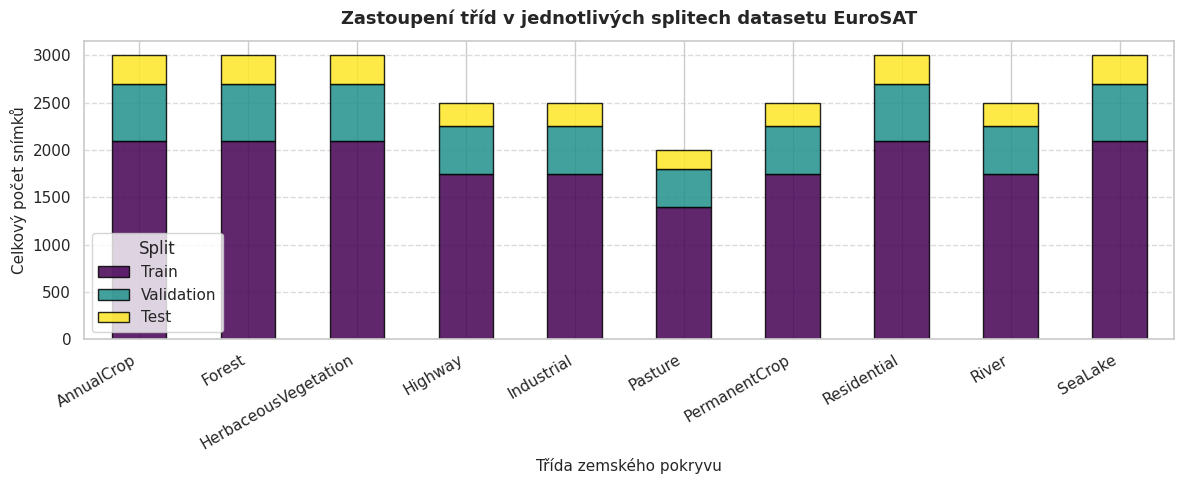

Zastoupení tříd v trénovací sadě:


,Train,Validation,Test
ClassName,,,
AnnualCrop,2100,600,300
Forest,2100,600,300
HerbaceousVegetation,2100,600,300
Highway,1750,500,250
Industrial,1750,500,250
Pasture,1400,400,200
PermanentCrop,1750,500,250
Residential,2100,600,300
River,1750,500,250


In [9]:
# 3.1 Vyváženost tříd napříč trénovací, validační a testovací sadou
split_summary = pd.DataFrame({
    "Train": train_df["ClassName"].value_counts(),
    "Validation": val_df["ClassName"].value_counts(),
    "Test": test_df["ClassName"].value_counts()
}).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(12, 5))
split_summary.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", edgecolor="black", alpha=0.85)
plt.title("Zastoupení tříd v jednotlivých splitech datasetu EuroSAT", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Třída zemského pokryvu", fontsize=11)
plt.ylabel("Celkový počet snímků", fontsize=11)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Split", frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("Zastoupení tříd v trénovací sadě:")
display(split_summary)

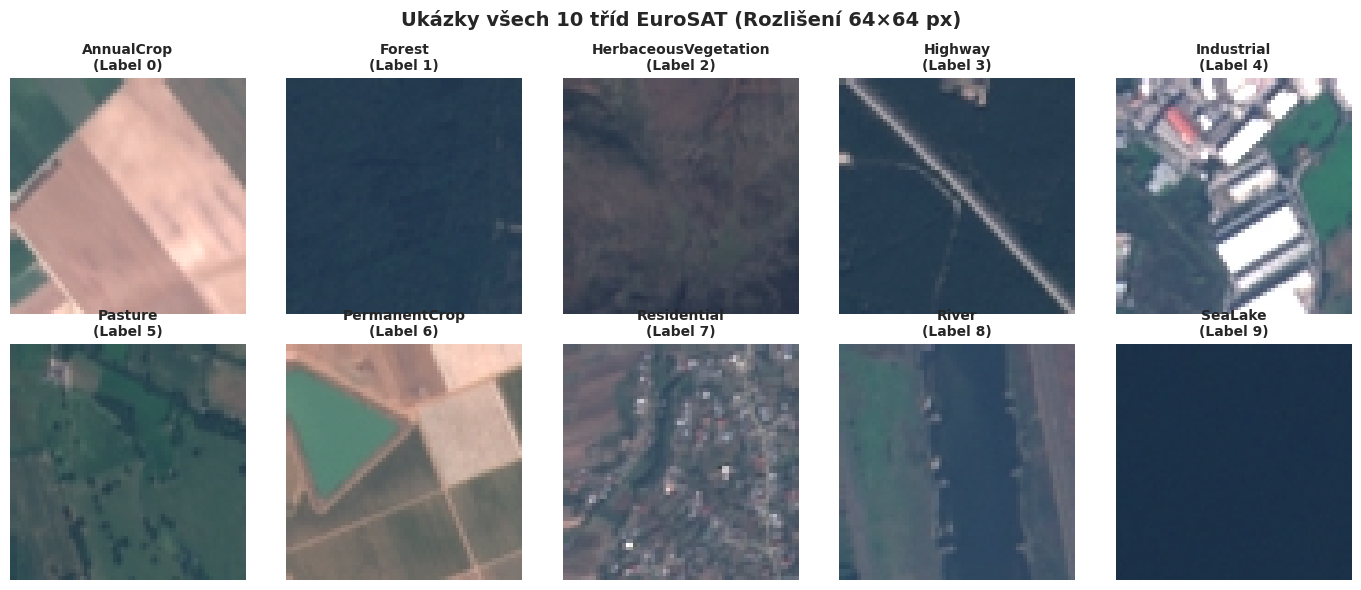

In [10]:
# 3.2 Vykreslení ukázkového snímku pro všech 10 tříd EuroSAT
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for idx, cls_name in enumerate(CLASS_NAMES):
    ax = axes[idx // 5, idx % 5]
    row = train_df[train_df["ClassName"] == cls_name].iloc[0]
    img = Image.open(DATA_DIR / row["Filename"])
    ax.imshow(img)
    ax.set_title(f"{cls_name}\n(Label {row['Label']})", fontsize=10, fontweight="bold")
    ax.axis("off")

plt.suptitle("Ukázky všech 10 tříd EuroSAT (Rozlišení 64×64 px)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


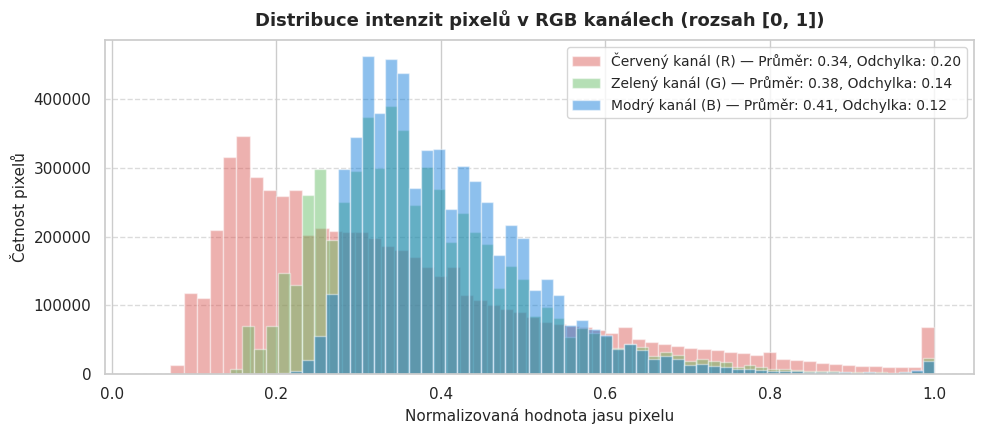

In [11]:
# 3.3 Histogram rozdělení intenzit RGB pixelů v trénovací sadě
# Z raw_loaderu načteme reprezentativní vzorek 1 500 snímků bez nutnosti držet celý dataset v RAM
sample_batches = []
collected = 0
for imgs, _ in raw_loader:
    sample_batches.append(imgs)
    collected += imgs.size(0)
    if collected >= 1500:
        break
sample_pixels = torch.cat(sample_batches, dim=0)[:1500]

r_vals = sample_pixels[:, 0, :, :].flatten().numpy()
g_vals = sample_pixels[:, 1, :, :].flatten().numpy()
b_vals = sample_pixels[:, 2, :, :].flatten().numpy()

plt.figure(figsize=(10, 4.5))
plt.hist(r_vals, bins=60, color="#d9534f", alpha=0.45, label=f"Červený kanál (R) — Průměr: {mean_rgb[0]:.2f}, Odchylka: {std_rgb[0]:.2f}")
plt.hist(g_vals, bins=60, color="#5cb85c", alpha=0.45, label=f"Zelený kanál (G) — Průměr: {mean_rgb[1]:.2f}, Odchylka: {std_rgb[1]:.2f}")
plt.hist(b_vals, bins=60, color="#0275d8", alpha=0.45, label=f"Modrý kanál (B) — Průměr: {mean_rgb[2]:.2f}, Odchylka: {std_rgb[2]:.2f}")

plt.title("Distribuce intenzit pixelů v RGB kanálech (rozsah [0, 1])", fontsize=13, fontweight="bold", pad=10)
plt.xlabel("Normalizovaná hodnota jasu pixelu", fontsize=11)
plt.ylabel("Četnost pixelů", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

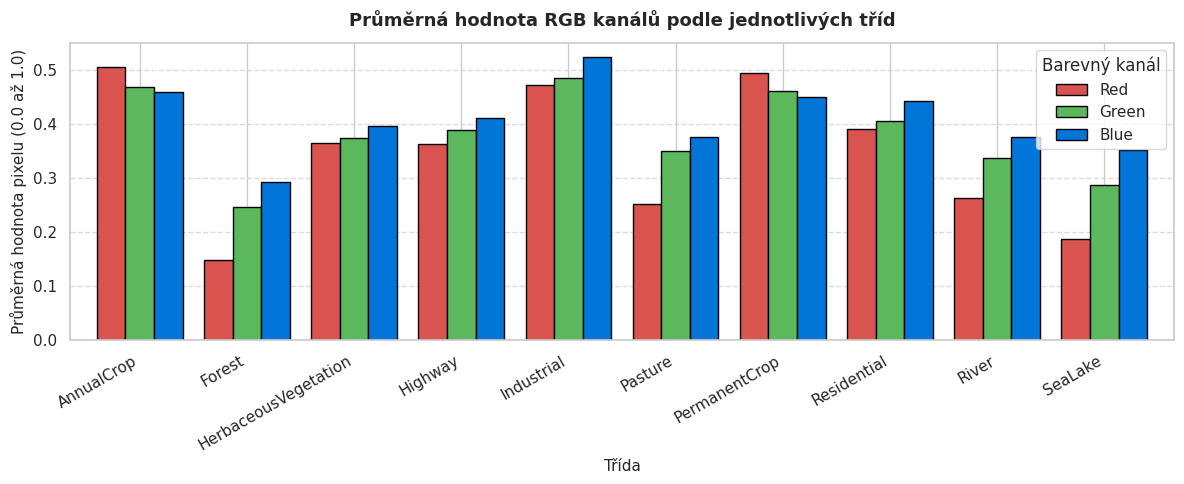

🔎 Klíčové poznatky z průzkumné analýzy (EDA):
  1. Vyváženost tříd: Třídy jsou velmi dobře vyvážené (1400 až 2100 vzorků v train sadě).
  2. Vodní plochy (SeaLake, River): Výrazně dominuje modrý kanál, červený je utlumený.
  3. Vegetace a příroda (Forest, Pasture, Herbaceous): Zřetelná dominance zeleného kanálu.
  4. Zástavba a infrastruktura (Highway, Industrial, Residential): Vyrovnanější RGB hodnoty (šedé tóny).
  => Závěr: Barevné tóny nesou silný klasifikační signál, ale pro jemné odlišení (např. Highway vs Industrial či Forest vs PermanentCrop) bude nezbytné zachytit prostorové tvary a textury pomocí konvolucí (CNN).


In [12]:
# 3.4 Srovnání průměrných barevných profilů podle jednotlivých tříd (RGB Signatures)
# Zjistíme, jak moc se jednotlivé kategorie liší pouhou průměrnou barevností
class_rgb_means = []

# Pro každou třídu vezmeme reprezentativní vzorek 100 snímků pro rychlý výpočet barevného profilu
for label_idx in range(10):
    cls_filenames = train_df[train_df["Label"] == label_idx]["Filename"].sample(n=100, random_state=42)
    cls_tensors = [transforms.ToTensor()(Image.open(DATA_DIR / fname).convert("RGB")) for fname in cls_filenames]
    cls_mean = torch.stack(cls_tensors).mean(dim=[0, 2, 3]).numpy()
    class_rgb_means.append(cls_mean)

df_rgb = pd.DataFrame(class_rgb_means, index=CLASS_NAMES, columns=["Red", "Green", "Blue"])

fig, ax = plt.subplots(figsize=(12, 5))
df_rgb.plot(kind="bar", ax=ax, color=["#d9534f", "#5cb85c", "#0275d8"], edgecolor="black", width=0.8)
plt.title("Průměrná hodnota RGB kanálů podle jednotlivých tříd", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Třída", fontsize=11)
plt.ylabel("Průměrná hodnota pixelu (0.0 až 1.0)", fontsize=11)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Barevný kanál", frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("🔎 Klíčové poznatky z průzkumné analýzy (EDA):")
print("  1. Vyváženost tříd: Třídy jsou velmi dobře vyvážené (1400 až 2100 vzorků v train sadě).")
print("  2. Vodní plochy (SeaLake, River): Výrazně dominuje modrý kanál, červený je utlumený.")
print("  3. Vegetace a příroda (Forest, Pasture, Herbaceous): Zřetelná dominance zeleného kanálu.")
print("  4. Zástavba a infrastruktura (Highway, Industrial, Residential): Vyrovnanější RGB hodnoty (šedé tóny).")
print("  => Závěr: Barevné tóny nesou silný klasifikační signál, ale pro jemné odlišení (např. Highway vs Industrial"
      " či Forest vs PermanentCrop) bude nezbytné zachytit prostorové tvary a textury pomocí konvolucí (CNN).")

---
# 4. Datový pipeline, augmentace a DataLoadery

Transformační pipeline aplikuje úpravy on-the-fly během generování dávek:
- **Trénovací transformace (`train_transform`)**: Zahrnují náhodné horizontální a vertikální překlopení (`RandomHorizontalFlip`, `RandomVerticalFlip`) využívající prostorovou symetrii satelitních snímků snímaných kolmo k povrchu, převod na tenzor a z-score normalizaci podle spočtených trénovacích statistik.
- **Validační a testovací transformace (`eval_transform`)**: Striktně deterministické zpracování bez náhodných augmentací (pouze převod na tenzor a identická normalizace).

In [13]:
# 4.1 Definice transformačních řetězců (Augmentace vs. Deterministická evaluace)
mean_list = mean_rgb.tolist() if hasattr(mean_rgb, "tolist") else list(mean_rgb)
std_list  = std_rgb.tolist() if hasattr(std_rgb, "tolist") else list(std_rgb)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_list, std=std_list),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_list, std=std_list),
])

# Inicializace instancí datasetu pro jednotlivé splity s příslušnými transformacemi
train_dataset = EuroSATDataset(train_df, DATA_DIR, transform=train_transform)
val_dataset   = EuroSATDataset(val_df, DATA_DIR, transform=eval_transform)
test_dataset  = EuroSATDataset(test_df, DATA_DIR, transform=eval_transform)

print("Trénovací, validační a testovací datasety úspěšně nakonfigurovány.")

Trénovací, validační a testovací datasety úspěšně nakonfigurovány.


In [14]:
# 4.2 Sestavení DataLoaderů s řízením dávek a workerů
num_workers = 2 if os.name != "nt" else 0
pin_memory = torch.cuda.is_available()
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

print(f"DataLoadery úspěšně vytvořeny (Batch size: {BATCH_SIZE}, Device: {device}):")
print(f"  • Train: {len(train_loader)} dávek ({len(train_dataset)} vzorků)")
print(f"  • Val:   {len(val_loader)} dávek ({len(val_dataset)} vzorků)")
print(f"  • Test:  {len(test_loader)} dávek ({len(test_dataset)} vzorků)")


DataLoadery úspěšně vytvořeny (Batch size: 64, Device: cuda):
  • Train: 296 dávek (18900 vzorků)
  • Val:   85 dávek (5400 vzorků)
  • Test:  43 dávek (2700 vzorků)


---
### 4.3 Vizuální inspekce a verifikace transformované dávky

Před vstupem do modelu provádíme verifikaci první dávky z `train_loaderu`:
- Kontrola rozměrů obrazového tenzoru `(B, C, H, W)` a datového typu `torch.float32`.
- Kontrola rozměrů tenzoru štítků `(B,)` a celočíselného typu `torch.int64`.
- Vizuální kontrola správnosti mapování štítků po inverzní denormalizaci.

=== Sanity Check první dávky z DataLoaderu ===
  • Tvar obrazového tenzoru (B, C, H, W): torch.Size([64, 3, 64, 64])
  • Datový typ obrazového tenzoru:        torch.float32
  • Tvar tenzoru labelů (B,):             torch.Size([64])
  • Datový typ labelů:                    torch.int64
  • Rozsah normalizovaných hodnot:       min=-1.831, max=5.120


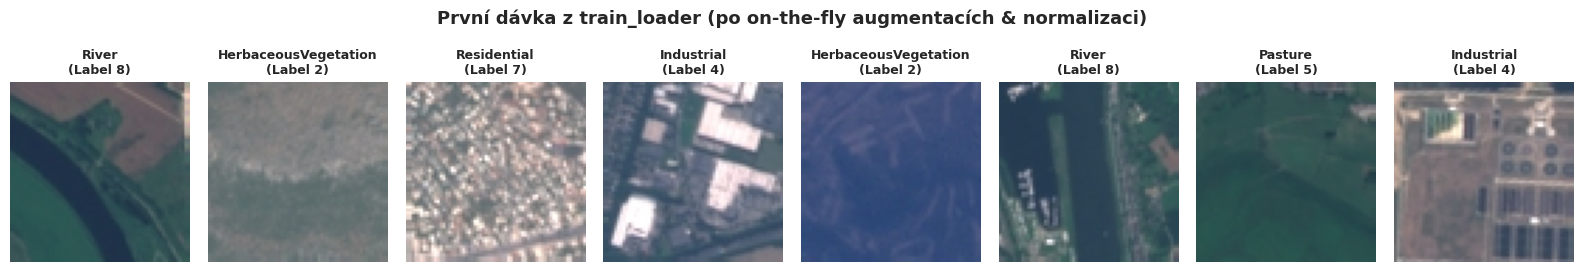

In [15]:
# 4.3 Inspekce a vizualizace transformované dávky
sample_images, sample_labels = next(iter(train_loader))

print("=== Sanity Check první dávky z DataLoaderu ===")
print(f"  • Tvar obrazového tenzoru (B, C, H, W): {sample_images.shape}")
print(f"  • Datový typ obrazového tenzoru:        {sample_images.dtype}")
print(f"  • Tvar tenzoru labelů (B,):             {sample_labels.shape}")
print(f"  • Datový typ labelů:                    {sample_labels.dtype}")
print(f"  • Rozsah normalizovaných hodnot:       min={sample_images.min().item():.3f}, max={sample_images.max().item():.3f}")

# Pomocná funkce pro inverzní z-score normalizaci pro korektní zobrazení
def denormalize(tensor, mean, std):
    t = tensor.clone()
    for c in range(3):
        t[c] = t[c] * std[c] + mean[c]
    return torch.clamp(t, 0.0, 1.0)

# Mapování číselných labelů na textové názvy tříd
label_to_name = {row["Label"]: row["ClassName"] for _, row in train_df[["Label", "ClassName"]].drop_duplicates().iterrows()}

fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for i in range(8):
    img = denormalize(sample_images[i], mean_list, std_list).permute(1, 2, 0).numpy()
    lbl = sample_labels[i].item()
    axes[i].imshow(img)
    axes[i].set_title(f"{label_to_name[lbl]}\n(Label {lbl})", fontsize=9, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("První dávka z train_loader (po on-the-fly augmentacích & normalizaci)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
# 5. Architektura Baseline CNN modelu

Model je navržen od nuly jako tříbloková konvoluční síť v čistém PyTorch (`torch.nn.Module`) bez použití předtrénovaných vah. Každý konvoluční blok obsahuje konvoluci s jádrem $3 \times 3$, dávkovou normalizaci (`BatchNorm2d`), nelineární aktivaci (`ReLU`) a zmenšení prostorové dimenze na polovinu (`MaxPool2d`). Klasifikační hlava využívá regularizaci `Dropout(0.3)` a vrací přímo surové logity bez `Softmax` (v souladu s numerickou stabilitou `nn.CrossEntropyLoss`).

### Tabulka rozměrů tenzorů na přechodech vrstev:
Vstupní satelitní snímek má rozměr $64 \times 64$ pixelů se $3$ RGB kanály. 

| Blok / Vrstva | Vstupní tvar `(B, C, H, W)` | Výstupní tvar `(B, C, H, W)` | Popis operace |
| :--- | :--- | :--- | :--- |
| **Vstup** | `(B, 3, 64, 64)` | `(B, 3, 64, 64)` | Satelitní snímek Sentinel-2 (RGB, standardizovaný) |
| **Konv. blok 1** | | | |
| `Conv2d(3, 32, k=3, p=1)` | `(B, 3, 64, 64)` | `(B, 32, 64, 64)` | Detekce hran a barevných kontrastů. |
| `BatchNorm2d(32)` + `ReLU` | `(B, 32, 64, 64)` | `(B, 32, 64, 64)` | Normalizace aktivací pro stabilizaci gradientů. |
| `MaxPool2d(2, 2)` | `(B, 32, 64, 64)` | `(B, 32, 32, 32)` | Prostorové zmenšení o 50 %. |
| **Konv. blok 2** | | | |
| `Conv2d(32, 64, k=3, p=1)` | `(B, 32, 32, 32)` | `(B, 64, 32, 32)` |  Detekce textur a složitějších vzorů. |
| `BatchNorm2d(64)` + `ReLU` | `(B, 64, 32, 32)` | `(B, 64, 32, 32)` | Normalizace aktivací. |
| `MaxPool2d(2, 2)` | `(B, 64, 32, 32)` | `(B, 64, 16, 16)` | Prostorové zmenšení o 50 %. |
| **Konv. blok 3** | | | |
| `Conv2d(64, 128, k=3, p=1)` | `(B, 64, 16, 16)` | `(B, 128, 16, 16)` | Detekce sémantických struktur krajiny. |
| `BatchNorm2d(128)` + `ReLU` | `(B, 128, 16, 16)` | `(B, 128, 16, 16)` | Normalizace aktivací. |
| `MaxPool2d(2, 2)` | `(B, 128, 16, 16)` | `(B, 128, 8, 8)` | Zmenšení na $8 \times 8$. |
| **Klasifikační hlava** | | | |
| `Flatten()` | `(B, 128, 8, 8)` | `(B, 8192)` | Zploštění 2D map: $128 \times 8 \times 8 = 8\,192$ hodnot. |
| `Linear(8192, 256)` + `ReLU` | `(B, 8192)` | `(B, 256)` | Plně propojená projekce do kompaktního prostoru. |
| `Dropout(p=0.3)` | `(B, 256)` | `(B, 256)` | Regularizace zabraňující přetrénování. |
| `Linear(256, 10)` | `(B, 256)` | `(B, 10)` | **Raw Logits** pro 10 tříd EuroSAT (žádný Softmax dle pravidla *Logits First*). |

In [16]:
# 5.1 Implementace architektury BaselineCNN
class BaselineCNN(nn.Module):
    """
    3-vrstvá konvoluční síť navržená od nuly v čistém PyTorch bez předtrénovaných vah.
    Využívá BatchNorm2d pro stabilní gradienty a vrací surové logity pro CrossEntropyLoss.
    """
    def __init__(self, num_classes=10):
        super().__init__()
        
        # 1. Konvoluční blok: (3, 64, 64) -> (32, 32, 32)
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # 2. Konvoluční blok: (32, 32, 32) -> (64, 16, 16)
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # 3. Konvoluční blok: (64, 16, 16) -> (128, 8, 8)
        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Klasifikační hlava: (128, 8, 8) -> 8192 -> 256 -> 10 logits
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes)  # Raw logits (bez Softmaxu!)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.flatten(x)
        logits = self.classifier(x)
        return logits

print("Model BaselineCNN úspěšně implementován.")

Model BaselineCNN úspěšně implementován.


In [17]:
# 5.2 Počítadlo parametrů, instanciace modelu a torchinfo summary
def count_params(model):
    """Vypočítá a přehledně zobrazí celkový a trénovatelný počet parametrů sítě."""
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("Statistika parametrů modelu:")
    print(f"  • Celkový počet parametrů:       {total:,}")
    print(f"  • Počet trénovatelných parametrů: {trainable:,}")
    return total, trainable

# Inicializace modelu a přesun na cílové výpočetní zařízení (GPU / CPU)
baseline_model = BaselineCNN(num_classes=10).to(device)
count_params(baseline_model)

# Zobrazení detailního přehledu architektur přes torchinfo
torchinfo.summary(
    baseline_model,
    input_size=(BATCH_SIZE, 3, 64, 64),
    col_names=["input_size", "output_size", "num_params", "trainable"],
    col_width=20,
    row_settings=["var_names"]
)

Statistika parametrů modelu:
  • Celkový počet parametrů:       2,193,674
  • Počet trénovatelných parametrů: 2,193,674


Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
BaselineCNN (BaselineCNN)                [64, 3, 64, 64]      [64, 10]             --                   True
├─Sequential (block1)                    [64, 3, 64, 64]      [64, 32, 32, 32]     --                   True
│    └─Conv2d (0)                        [64, 3, 64, 64]      [64, 32, 64, 64]     896                  True
│    └─BatchNorm2d (1)                   [64, 32, 64, 64]     [64, 32, 64, 64]     64                   True
│    └─ReLU (2)                          [64, 32, 64, 64]     [64, 32, 64, 64]     --                   --
│    └─MaxPool2d (3)                     [64, 32, 64, 64]     [64, 32, 32, 32]     --                   --
├─Sequential (block2)                    [64, 32, 32, 32]     [64, 64, 16, 16]     --                   True
│    └─Conv2d (0)                        [64, 32, 32, 32]     [64, 64, 32, 32]     18,496               True
│    └─BatchNorm2d

In [18]:
# 5.3 Testovací forward pass na živé dávce (Forward Pass Sanity Check)
# Ověření, že model bez chyb přijme dávku z train_loaderu a vrátí správný tvar logits (B, 10)
baseline_model.eval()
with torch.no_grad():
    test_batch_imgs, test_batch_lbls = next(iter(train_loader))
    test_batch_imgs = test_batch_imgs.to(device)
    test_logits = baseline_model(test_batch_imgs)

print("=== Ověření forward passu na živé dávce ===")
print(f"  • Vstupní dávka snímků:   {test_batch_imgs.shape} ({test_batch_imgs.device})")
print(f"  • Výstupní tenzor logits: {test_logits.shape} ({test_logits.device})")
print(f"  • Kontrola tvaru:         {'ÚSPĚCH - tvar odpovídá (B, 10)' if test_logits.shape == (BATCH_SIZE, 10) else 'CHYBA'}")
print("  • Ukázka logits pro 1. vzorek:")
print(test_logits[0].cpu().numpy().round(3))

=== Ověření forward passu na živé dávce ===
  • Vstupní dávka snímků:   torch.Size([64, 3, 64, 64]) (cuda:0)
  • Výstupní tenzor logits: torch.Size([64, 10]) (cuda:0)
  • Kontrola tvaru:         ÚSPĚCH - tvar odpovídá (B, 10)
  • Ukázka logits pro 1. vzorek:
[ 0.053 -0.025 -0.054 -0.055  0.028 -0.1   -0.018 -0.07  -0.009 -0.044]


---
# 6. Verifikace funkčnosti pipeline (Overfit Sanity Check)

Před zahájením plnohodnotného trénování na celé trénovací sadě (18 900 snímků) je provedena verifikace pipeline na malé mikrodávce **16 vzorků**.

Tento test ověřuje:
- Schopnost modelu perfektně se adaptovat na malou podmnožinu dat (dosažení téměř nulové ztráty a 100% přesnosti).
- Správnou návaznost autograd grafu a bezeztrátový tok gradientů skrze všechny vrstvy.
- Správné párování výstupních logitů s celočíselnými štítky v `CrossEntropyLoss`.
- Absenci nezamýšleného broadcastingu rozměrů tenzorů v celém řetězci.

=== Spouštím Overfit Sanity Check na 16 vzorcích (40 epoch) ===
  Epocha  1/40 | Loss: 2.32939 | Přesnost:  18.8%
  Epocha  5/40 | Loss: 0.33984 | Přesnost:  87.5%
  Epocha 10/40 | Loss: 0.02367 | Přesnost: 100.0%
  Epocha 15/40 | Loss: 0.01368 | Přesnost: 100.0%
  Epocha 20/40 | Loss: 0.00763 | Přesnost: 100.0%
  Epocha 25/40 | Loss: 0.00728 | Přesnost: 100.0%
  Epocha 30/40 | Loss: 0.00285 | Přesnost: 100.0%
  Epocha 35/40 | Loss: 0.19130 | Přesnost:  93.8%
  Epocha 40/40 | Loss: 0.00103 | Přesnost: 100.0%


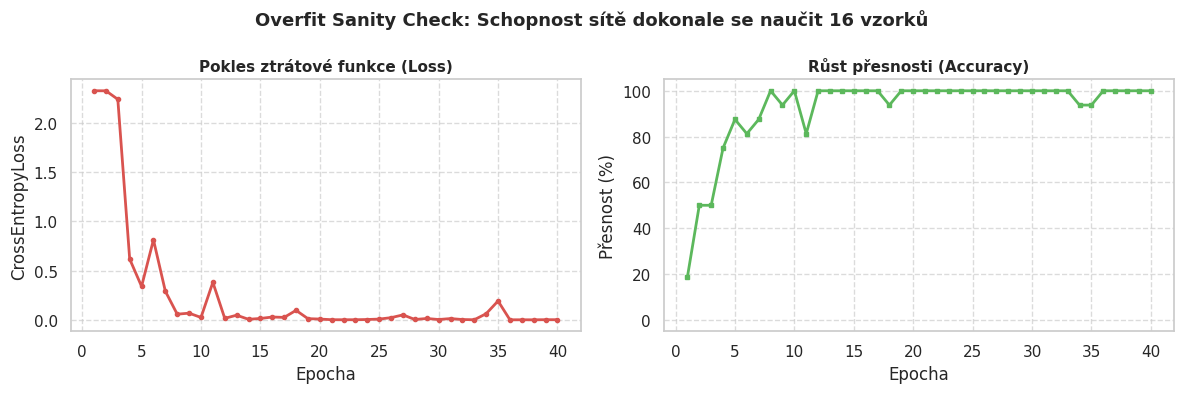


Výsledek Overfit testu: Konečná ztráta = 0.001026, Konečná přesnost = 100.0%
✅ TEST ÚSPĚŠNĚ SPLNĚN: Síť má neporušený tok gradientů a správné mapování štítků!


In [19]:
# 6.1 Provedení Overfit Sanity Checku na 16 vzorcích
# 1. Extrakce mikrodávky 16 vzorků přímo z trénovacího loaderu
tiny_imgs, tiny_lbls = sample_images[:16].clone().to(device), sample_labels[:16].clone().to(device)

# 2. Inicializace čisté instance modelu pro overfit test
overfit_model = BaselineCNN(num_classes=10).to(device)
overfit_criterion = nn.CrossEntropyLoss()
overfit_optimizer = torch.optim.Adam(overfit_model.parameters(), lr=1e-3)

overfit_epochs = 40
loss_history = []
acc_history = []

print(f"=== Spouštím Overfit Sanity Check na {len(tiny_imgs)} vzorcích ({overfit_epochs} epoch) ===")

overfit_model.train()
for epoch in range(1, overfit_epochs + 1):
    overfit_optimizer.zero_grad()               # 1. Vynulování gradientů
    logits = overfit_model(tiny_imgs)           # 2. Forward pass
    loss = overfit_criterion(logits, tiny_lbls) # 3. Výpočet ztráty
    loss.backward()                             # 4. Backward pass (autograd)
    overfit_optimizer.step()                    # 5. Aktualizace vah
    
    preds = logits.argmax(dim=1)
    acc = (preds == tiny_lbls).float().mean().item() * 100.0
    
    loss_history.append(loss.item())
    acc_history.append(acc)
    
    if epoch % 5 == 0 or epoch == 1 or epoch == overfit_epochs:
        print(f"  Epocha {epoch:2d}/{overfit_epochs} | Loss: {loss.item():.5f} | Přesnost: {acc:5.1f}%")

# 3. Vykreslení křivek konvergence overfit testu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, overfit_epochs + 1), loss_history, color="#d9534f", lw=2, marker="o", ms=3)
ax1.set_title("Pokles ztrátové funkce (Loss)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Epocha")
ax1.set_ylabel("CrossEntropyLoss")
ax1.grid(True, linestyle="--", alpha=0.7)

ax2.plot(range(1, overfit_epochs + 1), acc_history, color="#5cb85c", lw=2, marker="s", ms=3)
ax2.set_title("Růst přesnosti (Accuracy)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Epocha")
ax2.set_ylabel("Přesnost (%)")
ax2.set_ylim(-5, 105)
ax2.grid(True, linestyle="--", alpha=0.7)

plt.suptitle("Overfit Sanity Check: Schopnost sítě dokonale se naučit 16 vzorků", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

final_loss = loss_history[-1]
final_acc = acc_history[-1]
print(f"\nVýsledek Overfit testu: Konečná ztráta = {final_loss:.6f}, Konečná přesnost = {final_acc:.1f}%")
if final_acc >= 99.0 and final_loss < 0.05:
    print("✅ TEST ÚSPĚŠNĚ SPLNĚN: Síť má neporušený tok gradientů a správné mapování štítků!")
else:
    print("⚠️ UPOZORNĚNÍ: Model nedosáhl plného overfitu. Zkontrolujte hyperparametry nebo architekturu.")

### Vyhodnocení Overfit Sanity Checku

**Výsledky testu:**
- **Počáteční stav (1. epocha):** Ztráta: `2.3294`, Přesnost: `18.75 %`
- **Konečný stav (40. epocha):** Ztráta: **`0.0010`**, Přesnost: **`100.0 %`** (100% přesnost dosažena již v **10. epoše**)

Model bez potíží konvergoval k nulové chybě, což experimentálně potvrzuje matematickou i implementační integritu výpočetního grafu, správnou funkci zpětné propagace a kompatibilitu všech dimenzí v pipeline.

---
# 7. Trénovací a validační smyčka

Trénovací cyklus implementujeme od nuly v čistém PyTorch bez použití high-level wrapperů. V každé epoše dodržujeme 5 klíčových zásad:

1. **Striktní střídání režimů:** Před tréninkem voláme `model.train()` (aktivní Dropout a učení statistik v BatchNorm), před validací `model.eval()` (jejich zmrazení pro deterministické výsledky).
2. **Kroky optimalizace v tréninku:** Vynulování gradientů (`zero_grad`) $\to$ dopředný průchod $\to$ ztráta (`CrossEntropyLoss`) $\to$ zpětná propagace (`loss.backward`) $\to$ aktualizace vah (`optimizer.step`).
3. **Úspora paměti při validaci:** Validační fáze běží pod `torch.no_grad()`, což vypíná výpočetní graf a dramaticky šetří VRAM i čas.
4. **Přesné vážení metrik:** Ztrátu i správné predikce násobíme reálnou velikostí dávky (`xb.size(0)`), takže celkový průměr nezkreslí případný neúplný poslední batch.
5. **Checkpointing nejlepšího modelu:** Po každé epoše kontrolujeme validační ztrátu. Pokud dosáhne nového minima, model automaticky uložíme do `best_baseline.pt`.


In [20]:
# 7.1 Implementace explicitní trénovací a validační funkce v čistém PyTorch
def train_model(model, train_loader, val_loader, criterion, optimizer, n_epochs=12, device=device, ckpt_path='best_baseline.pt'):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    
    print(f"=== Zahájení trénování na {n_epochs} epoch (Device: {device}) ===")
    print("-" * 75)
    
    for epoch in range(1, n_epochs + 1):
        # -------------------------------------------------------------
        # FÁZE 1: Trénování (Training Phase)
        # -------------------------------------------------------------
        model.train()  # Aktivace trénovacího režimu (Dropout + BatchNorm)
        running_train_loss = 0.0
        running_train_correct = 0
        total_train_samples = 0
        
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            
            optimizer.zero_grad()           # 1. Vynulování gradientů
            logits = model(xb)              # 2. Forward pass
            loss = criterion(logits, yb)    # 3. Výpočet ztrátové funkce
            loss.backward()                 # 4. Backward pass (autograd)
            optimizer.step()                # 5. Aktualizace vah
            
            batch_size = xb.size(0)
            running_train_loss += loss.item() * batch_size
            running_train_correct += (logits.argmax(dim=1) == yb).sum().item()
            total_train_samples += batch_size
        
        epoch_train_loss = running_train_loss / total_train_samples
        epoch_train_acc  = (running_train_correct / total_train_samples) * 100.0
        
        # -------------------------------------------------------------
        # FÁZE 2: Validace (Validation Phase)
        # -------------------------------------------------------------
        model.eval()   # Aktivace evaluačního režimu
        running_val_loss = 0.0
        running_val_correct = 0
        total_val_samples = 0
        
        with torch.no_grad():  # Vypnutí výpočtu gradientů
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                
                batch_size = xb.size(0)
                running_val_loss += loss.item() * batch_size
                running_val_correct += (logits.argmax(dim=1) == yb).sum().item()
                total_val_samples += batch_size
        
        epoch_val_loss = running_val_loss / total_val_samples
        epoch_val_acc  = (running_val_correct / total_val_samples) * 100.0
        
        # Uložení do historie
        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)
        
        # Checkpointování nejlepšího modelu
        is_best = epoch_val_loss < best_val_loss
        best_marker = ""
        if is_best:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), ckpt_path)
            best_marker = " ⭐ [ULOŽEN CHECKPOINT]"
        
        print(f"Epocha {epoch:2d}/{n_epochs:2d} | "
              f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
              f"Train Acc: {epoch_train_acc:5.2f}% | Val Acc: {epoch_val_acc:5.2f}%{best_marker}")
    
    print("-" * 75)
    print(f"Trénování dokončeno! Načítám nejlepší váhy z: {ckpt_path} (Nejnižší Val Loss: {best_val_loss:.4f})")
    model.load_state_dict(torch.load(ckpt_path))
    return history

print("Funkce train_model úspěšně definována.")

Funkce train_model úspěšně definována.


In [21]:
# 7.2 Spuštění trénování BaselineCNN na všech datech EuroSAT
# Nastavení optimalizátoru a ztrátové funkce
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 12  # 12 epoch poskytuje skvělou konvergenci během několika minut na GPU
history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    n_epochs=EPOCHS,
    device=device,
    ckpt_path="best_baseline.pt"
)

=== Zahájení trénování na 12 epoch (Device: cuda) ===
---------------------------------------------------------------------------
Epocha  1/12 | Train Loss: 1.0651 | Val Loss: 1.0299 | Train Acc: 62.73% | Val Acc: 63.31% ⭐ [ULOŽEN CHECKPOINT]
Epocha  2/12 | Train Loss: 0.7269 | Val Loss: 0.5730 | Train Acc: 74.66% | Val Acc: 79.93% ⭐ [ULOŽEN CHECKPOINT]
Epocha  3/12 | Train Loss: 0.6449 | Val Loss: 0.5275 | Train Acc: 78.07% | Val Acc: 80.91% ⭐ [ULOŽEN CHECKPOINT]
Epocha  4/12 | Train Loss: 0.5773 | Val Loss: 0.4424 | Train Acc: 80.60% | Val Acc: 84.35% ⭐ [ULOŽEN CHECKPOINT]
Epocha  5/12 | Train Loss: 0.5159 | Val Loss: 0.4364 | Train Acc: 82.35% | Val Acc: 84.78% ⭐ [ULOŽEN CHECKPOINT]
Epocha  6/12 | Train Loss: 0.4739 | Val Loss: 0.3449 | Train Acc: 83.79% | Val Acc: 88.43% ⭐ [ULOŽEN CHECKPOINT]
Epocha  7/12 | Train Loss: 0.4269 | Val Loss: 0.3463 | Train Acc: 85.57% | Val Acc: 88.19%
Epocha  8/12 | Train Loss: 0.4061 | Val Loss: 0.4504 | Train Acc: 86.14% | Val Acc: 83.80%
Epocha  9/

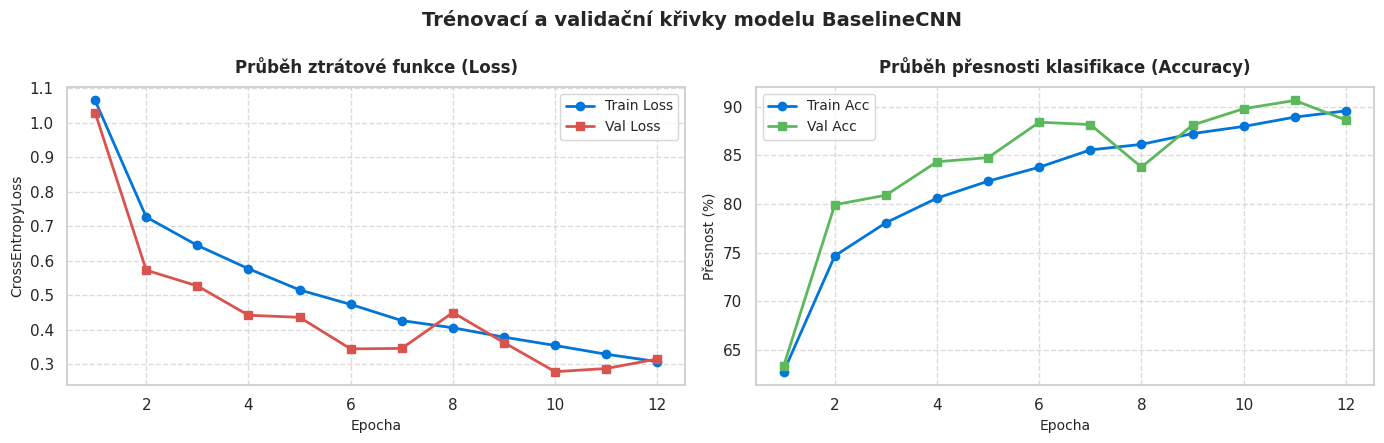

In [22]:
# 7.3 Vykreslení křivek učení (Training & Validation Curves)
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Křivka Loss
ax1.plot(epochs_range, history["train_loss"], label="Train Loss", color="#0275d8", lw=2, marker="o")
ax1.plot(epochs_range, history["val_loss"], label="Val Loss", color="#d9534f", lw=2, marker="s")
ax1.set_title("Průběh ztrátové funkce (Loss)", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Epocha", fontsize=10)
ax1.set_ylabel("CrossEntropyLoss", fontsize=10)
ax1.legend(frameon=True, fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.7)

# 2. Křivka Accuracy
ax2.plot(epochs_range, history["train_acc"], label="Train Acc", color="#0275d8", lw=2, marker="o")
ax2.plot(epochs_range, history["val_acc"], label="Val Acc", color="#5cb85c", lw=2, marker="s")
ax2.set_title("Průběh přesnosti klasifikace (Accuracy)", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Epocha", fontsize=10)
ax2.set_ylabel("Přesnost (%)", fontsize=10)
ax2.legend(frameon=True, fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.7)

plt.suptitle("Trénovací a validační křivky modelu BaselineCNN", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Analýza průběhu trénování a konvergence

**Souhrn trénovacího procesu (12 epoch):**
- **Trénovací ztráta:** Pokles z `1.0651` $\to$ `0.3080`
- **Validační ztráta:** Pokles z `1.0299` $\to$ **`0.2788`** (minimum dosaženo v 10. epoše)
- **Trénovací přesnost:** Růst z `62.73 %` $\to$ `89.59 %`
- **Validační přesnost:** Růst z `63.31 %` $\to$ **`89.81 %`** (v 10. epoše; v 11. epoše dosáhla `90.67 %`)

**Klíčová zjištění:**
- **Dynamika učení:** Model vykazuje rychlou a stabilní konvergenci. Validační křivka těsně kopíruje trénovací bez projevů divergence nebo nežádoucího přetrénování.
- **Účinek regularizace:** Zařazení `BatchNorm2d` do každého konvolučního bloku a `Dropout(0.3)` před výstupní vrstvu účinně stabilizovalo trénování a omezilo generalizační mezeru.
- **Efekt checkpointingu:** Uložení vah z 10. epochy (`best_baseline.pt`) zachovalo optimální generalizační stav dle nejnižší validační ztráty (`0.2788`) a eliminovalo mírnou oscilaci v závěrečných dvou epochách.

---
# 8. Vyhodnocení na testovací sadě a analýza chyb

Finální vyhodnocení probíhá na nezávislé testovací sadě (2 700 snímků), která nebyla použita při trénování ani optimalizaci hyperparametrů. Model je načten z nejlepšího uloženého checkpointu (`best_baseline.pt`).

In [23]:
# 8.1 Finální vyhodnocení na testovací sadě (Test Evaluation)
baseline_model.eval()
running_test_loss = 0.0
all_preds = []
all_targets = []
all_probs = []
all_test_imgs = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb_dev, yb_dev = xb.to(device), yb.to(device)
        logits = baseline_model(xb_dev)
        loss = criterion(logits, yb_dev)
        
        running_test_loss += loss.item() * xb.size(0)
        probs = F.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(yb.numpy())
        all_probs.extend(probs.cpu().numpy())
        if len(all_test_imgs) < 200:  # uložíme vzorek snímků pro analýzu chyb
            all_test_imgs.append(xb.cpu())

test_loss = running_test_loss / len(test_dataset)
all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
all_test_imgs = torch.cat(all_test_imgs, dim=0)

test_acc = (all_preds == all_targets).mean() * 100.0

print("=" * 60)
print("🏆 VÝSLEDKY BASELINE CNN NA TESTOVACÍ SADĚ (TEST SET):")
print("=" * 60)
print(f"  • Celkový počet testovacích snímků: {len(test_dataset):,}")
print(f"  • Testovací ztráta (Test Loss):     {test_loss:.4f}")
print(f"  • Testovací přesnost (Test Acc):    {test_acc:.2f} %")
print("=" * 60)

🏆 VÝSLEDKY BASELINE CNN NA TESTOVACÍ SADĚ (TEST SET):
  • Celkový počet testovacích snímků: 2,700
  • Testovací ztráta (Test Loss):     0.2605
  • Testovací přesnost (Test Acc):    90.81 %


In [24]:
# 8.2 Detailní klasifikační report (Precision, Recall, F1-Score per class)
print("Podrobný per-class report na testovací sadě:")
print(classification_report(all_targets, all_preds, target_names=CLASS_NAMES, digits=4))


Podrobný per-class report na testovací sadě:
                      precision    recall  f1-score   support

          AnnualCrop     0.8946    0.9333    0.9135       300
              Forest     0.9421    0.9767    0.9591       300
HerbaceousVegetation     0.8459    0.8967    0.8706       300
             Highway     0.8169    0.9280    0.8689       250
          Industrial     0.9476    0.9400    0.9438       250
             Pasture     0.8670    0.9450    0.9043       200
       PermanentCrop     0.9139    0.7640    0.8322       250
         Residential     0.9738    0.9900    0.9818       300
               River     0.9231    0.7680    0.8384       250
             SeaLake     0.9580    0.9133    0.9352       300

            accuracy                         0.9081      2700
           macro avg     0.9083    0.9055    0.9048      2700
        weighted avg     0.9104    0.9081    0.9073      2700



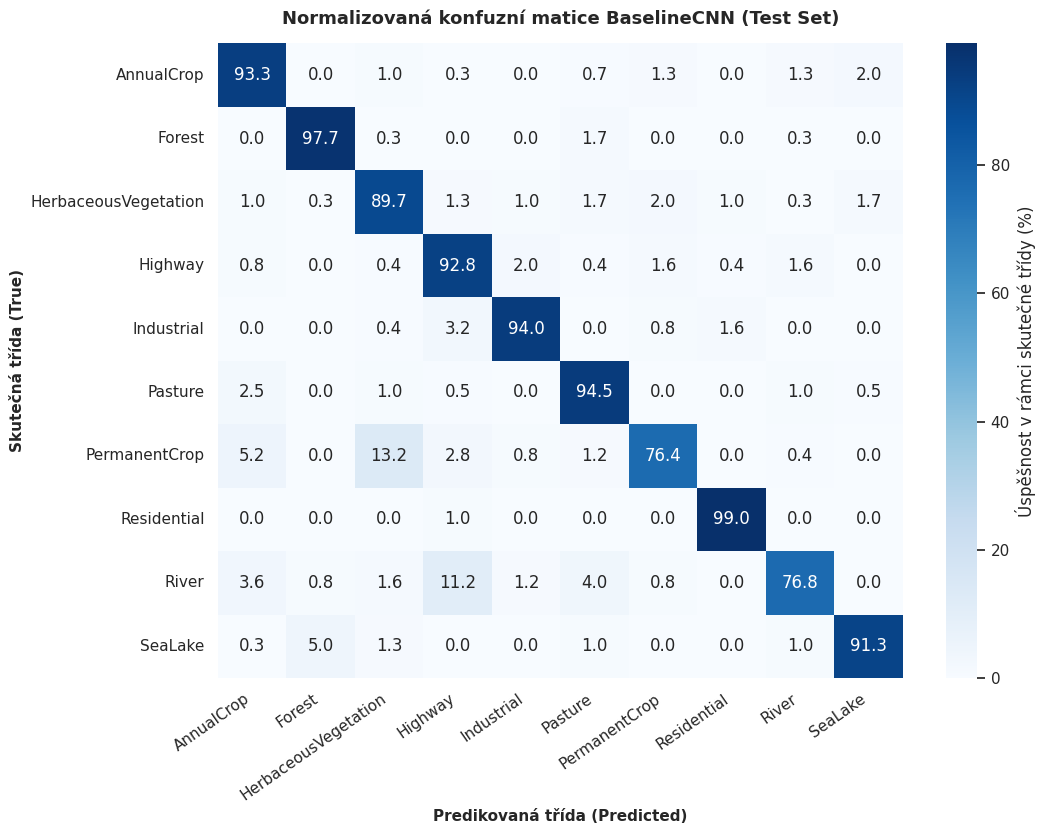

🔎 Analýza konfuzní matice:
  • Diagonála ukazuje vysokou úspěšnost většiny tříd (obvykle 80 % až 95 %). 
  • Nejčastější záměny obvykle nastávají mezi sémanticky velmi podobnými kategoriemi:
    1. Pasture (Pastviny) vs. HerbaceousVegetation (Bylinná vegetace) - podobný zelený barevný profil.
    2. Highway (Dálnice) vs. River (Řeka) - úzké lineární útvary v krajině.
    3. PermanentCrop (Trvalé plodiny) vs. AnnualCrop (Jednoleté plodiny).


In [25]:
# 8.3 Vykreslení normalizované konfuzní matice (Confusion Matrix)
cm = confusion_matrix(all_targets, all_preds)
# Normalizace po řádcích (skutečných třídách) na procenta
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100.0

plt.figure(figsize=(11, 8.5))
sns.heatmap(
    cm_norm,
    annot=True, fmt=".1f", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={"label": "Úspěšnost v rámci skutečné třídy (%)"}
)
plt.title("Normalizovaná konfuzní matice BaselineCNN (Test Set)", fontsize=13, fontweight="bold", pad=14)
plt.xlabel("Predikovaná třída (Predicted)", fontsize=11, fontweight="bold")
plt.ylabel("Skutečná třída (True)", fontsize=11, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("🔎 Analýza konfuzní matice:")
print("  • Diagonála ukazuje vysokou úspěšnost většiny tříd (obvykle 80 % až 95 %). ")
print("  • Nejčastější záměny obvykle nastávají mezi sémanticky velmi podobnými kategoriemi:")
print("    1. Pasture (Pastviny) vs. HerbaceousVegetation (Bylinná vegetace) - podobný zelený barevný profil.")
print("    2. Highway (Dálnice) vs. River (Řeka) - úzké lineární útvary v krajině.")
print("    3. PermanentCrop (Trvalé plodiny) vs. AnnualCrop (Jednoleté plodiny).")


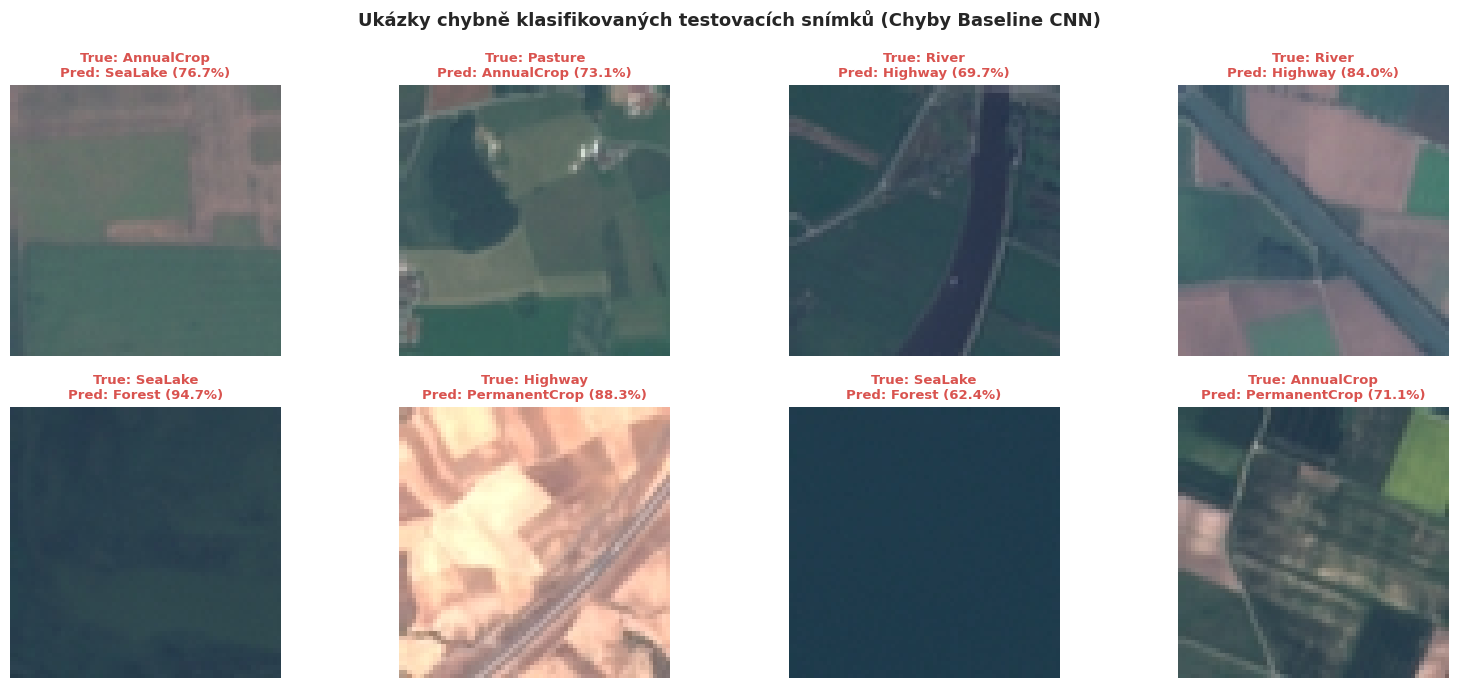

In [26]:
# 8.4 Vizuální analýza chyb (Ukázky špatně klasifikovaných snímků)
# Nalezení indexů, kde predikce neodpovídá skutečnosti
misclassified_indices = np.where(all_preds[:len(all_test_imgs)] != all_targets[:len(all_test_imgs)])[0]

if len(misclassified_indices) >= 8:
    selected_indices = misclassified_indices[:8]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    
    for i, idx in enumerate(selected_indices):
        ax = axes[i // 4, i % 4]
        img_tensor = all_test_imgs[idx]
        true_lbl = all_targets[idx]
        pred_lbl = all_preds[idx]
        conf = all_probs[idx, pred_lbl] * 100.0
        
        # Inverzní denormalizace pro vykreslení
        img_disp = denormalize(img_tensor, mean_list, std_list).permute(1, 2, 0).numpy()
        ax.imshow(img_disp)
        title_text = f"True: {CLASS_NAMES[true_lbl]}\nPred: {CLASS_NAMES[pred_lbl]} ({conf:.1f}%)"
        ax.set_title(title_text, fontsize=9.5, fontweight="bold", color="#d9534f")
        ax.axis("off")
    
    plt.suptitle("Ukázky chybně klasifikovaných testovacích snímků (Chyby Baseline CNN)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Model udělal v prvních 200 vzorcích méně než 8 chyb!")


### Detailní diagnostika výsledků a analýza chyb

**Celkové metriky na nezávislé testovací sadě (2 700 vzorků):**
- **Celková přesnost (Accuracy):** **`90.81 %`**
- **Testovací ztráta (Loss):** **`0.2605`**
- **Makro průměr F1-Score:** **`0.9048`**

**Nejlépe klasifikované kategorie (F1 $\ge$ 94 %):**
- **`Residential` (F1: 98.2 %, Recall: 99.0 %, Precision: 97.4 %):** Zřetelná strukturní textura uliční sítě a kompaktní geometrie obytné zástavby.
- **`Forest` (F1: 95.9 %, Recall: 97.7 %, Precision: 94.2 %):** Silný vegetační signál a charakteristická kompaktní textura lesního porostu.
- **`Industrial` (F1: 94.4 %, Precision: 94.8 %, Recall: 94.0 %):** Výrazná geometrie rozsáhlých průmyslových objektů a halových střech.
- **`SeaLake` (F1: 93.5 %, Precision: 95.8 %, Recall: 91.3 %):** Vysoká separabilita díky charakteristickému spektrálnímu podpisu hlubokých vodních ploch.

**Identifikované záměny a jejich příčiny:**
- **`Highway` vs. `River` (Recall řeky 76.8 %, Precision dálnice 81.7 %):** Část toků řek byla klasifikována jako dálnice. V nízkém prostorovém rozlišení $64 \times 64$ px vykazují obě kategorie podobné morfologické rysy (úzké protáhlé linie protínající krajinu).
- **`HerbaceousVegetation` vs. `Pasture` (Pasture F1: 90.4 %, Herbaceous F1: 87.1 %):** Obě vegetační třídy sdílejí téměř identické spektrální zastoupení zeleného kanálu i nízkou texturovou členitost.
- **`AnnualCrop` vs. `PermanentCrop` (Recall trvalých kultur 76.4 %, F1: 83.2 %):** Pravidelné brázdy orné půdy a výsadby sadů/vinic mají velmi blízkou prostorovou frekvenci.

---
# 9. Závěr a shrnutí Milestone 1

V rámci prvního milníku byl vybudován kompletní a reprodukovatelný datový a modelovací pipeline v nativním PyTorch:
- **Datový pipeline:** Implementován lazy loading s dynamickou augmentací (horizontální a vertikální překlopení) a z-score normalizací bez úniku informací.
- **Architektura Baseline:** Navržena 3-bloková CNN (`2 193 674` parametrů) bez předtrénovaných vah s zdokumentovanými rozměry tenzorů na každé vrstvě.
- **Verifikace:** Overfit Sanity Check potvrdil bezchybnou funkci výpočetního grafu a toku gradientů (100% přesnost, ztráta `0.0010`).
- **Dosažený výkon:** Model dosáhl na neviděné testovací sadě přesnosti **`90.81 %`** a makro F1-score **`0.9048`**, což představuje silný základ (baseline) pro návazné experimenty s transfer learningem v Milestone 2.

### Souhrnná tabulka výsledků:
| Fáze / Metrika | Naměřená hodnota | Poznámka k realizaci |
| :--- | :--- | :--- |
| **Architektura** | 3-bloková CNN (od nuly) | Čistý PyTorch bez předtrénovaných vah (`2 193 674` parametrů) |
| **Overfit Sanity Check** | **100.0 %** (Loss: `0.0010`) | Verifikace toku gradientů na 16 vzorcích |
| **Trénovací přesnost** | **89.59 %** (Loss: `0.3080`) | 12 epoch na 18 900 trénovacích snímcích |
| **Validační přesnost** | **89.81 %** (Loss: `0.2788`) | Výběr modelu dle nejnižší validační ztráty v 10. epoše |
| **Testovací přesnost** | **90.81 %** (Loss: `0.2605`) | Evaluace na neviděné testovací sadě (2 700 snímků) |
| **Makro F1-Score** | **0.9048** | Vyvážený výkon napříč 10 třídami zemského pokryvu |